# Chapter 10 — Clustering Techniques

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

*Clustering* (klasterisasi) adalah tugas *unsupervised learning*: kita hanya punya matriks fitur $X$ tanpa label $y$, lalu ingin menemukan kelompok-kelompok alami — titik yang mirip dikumpulkan dalam satu klaster, titik yang berbeda dipisahkan. Clustering dipakai untuk segmentasi pelanggan, pengelompokan dokumen, kompresi warna gambar, deteksi anomali, hingga eksplorasi awal data sebelum membangun model terawasi. Chapter ini membahas algoritma klasik (**K-Means**, **Hierarchical/Agglomerative**, **DBSCAN**), cara **mengevaluasi** hasil klasterisasi tanpa (dan dengan) label, panduan **memilih algoritma** sesuai bentuk data, serta teknik lanjut (**Spectral Clustering** dan **Gaussian Mixture Models**).

**Daftar Isi**

1. 10.1 Persiapan Data untuk Clustering
2. 10.2 K-Means Clustering
3. 10.3 Hierarchical Clustering
4. 10.4 Density-Based Clustering dengan DBSCAN
5. 10.5 Metrik Evaluasi Klaster
6. 10.6 Memilih Algoritma Clustering yang Tepat
7. 10.7 Teknik Clustering Lanjutan (Spectral Clustering & GMM)
8. Latihan (Exercise 1–3: K-Means pada Iris, DBSCAN vs K-Means, PCA + GMM pada Wine)
9. Ringkasan Chapter 10

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 10 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 dan lebih informatif (misalnya mencetak ukuran klaster dan metrik), lalu menjelaskan teori di balik setiap resep (bagian **Teori:**) dan menafsirkan hasil eksekusinya (bagian **Interpretasi:**). Sel bertanda *Tambahan* bukan bagian dari notebook asli. Semua data berasal dari generator/dataset bawaan scikit-learn.

## Import Library

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

from sklearn.datasets import make_blobs, make_moons, make_circles, load_iris, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             calinski_harabasz_score, silhouette_samples)
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from IPython.display import display

# Pengaturan tampilan gambar agar ukurannya moderat
plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')
pd.set_option('display.width', 120)

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scipy        :', scipy.__version__)
print('scikit-learn :', sklearn.__version__)

numpy        : 2.5.4
pandas       : 3.1.0
scipy        : 1.16.3
scikit-learn : 1.9.1


## 10.1 Persiapan Data untuk Clustering

**Teori:**

**Apa itu clustering?** Diberikan $n$ titik $\mathbf x_1,\dots,\mathbf x_n \in \mathbb R^p$, clustering mencari partisi (atau penugasan lunak) ke dalam $K$ kelompok $C_1,\dots,C_K$ sedemikian sehingga kemiripan **di dalam** klaster tinggi dan kemiripan **antar** klaster rendah. Karena tidak ada label, "klaster yang benar" bergantung pada definisi kemiripan yang kita pilih — itulah sebabnya ada banyak keluarga algoritma:

| Keluarga | Gagasan | Contoh di scikit-learn |
|---|---|---|
| *Centroid-based* | Klaster diwakili titik pusat; titik masuk ke pusat terdekat | `KMeans`, `MiniBatchKMeans` |
| *Hierarchical* | Membangun pohon penggabungan/pemecahan klaster | `AgglomerativeClustering` |
| *Density-based* | Klaster = wilayah padat yang dipisahkan wilayah jarang | `DBSCAN`, `HDBSCAN`, `OPTICS` |
| *Graph-based* | Klaster = komponen graf kemiripan yang terhubung lemah | `SpectralClustering` |
| *Model-based* | Data dianggap sampel dari campuran distribusi | `GaussianMixture` |

**Jarak dan skala fitur.** Hampir semua algoritma di atas memakai jarak, umumnya Euclidean $d(\mathbf x,\mathbf z)=\lVert\mathbf x-\mathbf z\rVert_2=\sqrt{\sum_j (x_j-z_j)^2}$. Jarak ini sangat dipengaruhi skala: fitur bersatuan besar (misalnya pendapatan dalam rupiah) akan mendominasi fitur bersatuan kecil (misalnya umur). Karena itu data biasanya distandardisasi lebih dulu dengan **z-score**:

$$
z_{ij} = \frac{x_{ij}-\bar x_j}{s_j},
$$

sehingga setiap fitur memiliki rata-rata 0 dan simpangan baku 1 (`StandardScaler`).

**`make_blobs`** membangkitkan titik dari beberapa distribusi Gaussian isotropik: setiap pusat $\boldsymbol\mu_k$ dipilih acak (default di kotak $[-10,10]^p$) lalu titik diambil dari $\mathcal N(\boldsymbol\mu_k,\ \sigma^2 I)$ dengan $\sigma$ = `cluster_std`. Data seperti ini adalah kondisi ideal bagi K-Means. Perlu diingat bahwa pusat dipilih secara acak, sehingga dua blob bisa saja jatuh berdekatan dan saling tumpang tindih.

**Pitfall:** clustering *selalu* menghasilkan klaster, bahkan pada data yang sebenarnya tidak berkelompok. Karena itu langkah pertama yang baik adalah memvisualisasikan data (atau proyeksinya, misalnya dengan PCA) untuk melihat apakah struktur kelompok memang ada.

In [2]:
# Membuat dataset dummy: 300 titik, 4 pusat (blob) Gaussian
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)

# Standardisasi (z-score) agar kedua fitur berskala sama
X = StandardScaler().fit_transform(X)

print('Ukuran data         :', X.shape)
print('Rata-rata per fitur :', X.mean(axis=0).round(3))
print('Std per fitur       :', X.std(axis=0).round(3))

Ukuran data         : (300, 2)
Rata-rata per fitur : [0. 0.]
Std per fitur       : [1. 1.]


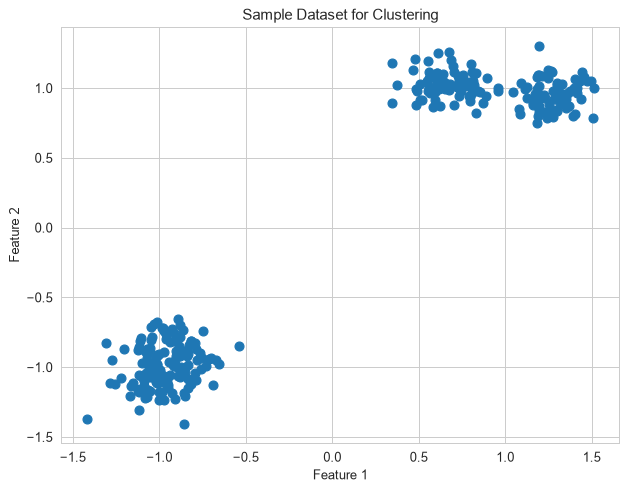

In [3]:
# Visualisasi data mentah (tanpa label)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Sample Dataset for Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Interpretasi:**

- Setelah `StandardScaler`, kedua fitur memiliki rata-rata **0** dan simpangan baku **1**, sehingga keduanya berkontribusi setara pada jarak Euclidean.
- Meskipun data dibangkitkan dari **4** pusat, scatter plot tidak memperlihatkan empat kelompok yang jelas. Dengan `random_state=2024`, pusat-pusat blob jatuh berpasangan: dalam satuan asli, dua pusat di kiri-bawah hanya berjarak ≈1.4 (bandingkan dengan `cluster_std=0.6`) sehingga keduanya **hampir berimpit** dan tampak sebagai satu gumpalan; dua pusat di kanan-atas berjarak ≈2.9 sehingga masih terlihat sebagai **dua gumpalan yang bersebelahan**. Jarak antar pasangan jauh lebih besar (≈14–17). Jadi struktur "sebenarnya" bersifat **hierarkis**: 2 kelompok besar → 3 gumpalan yang terlihat → 4 blob pembangkit. Fakta ini akan menjelaskan banyak hasil di bagian-bagian berikutnya.

## 10.2 K-Means Clustering

**Teori:**

**Fungsi objektif.** K-Means mencari $K$ centroid $\boldsymbol\mu_1,\dots,\boldsymbol\mu_K$ dan penugasan klaster yang meminimalkan *within-cluster sum of squares* (WCSS), yang di scikit-learn disebut **inertia**:

$$
J = \sum_{k=1}^{K}\ \sum_{\mathbf x_i \in C_k} \lVert \mathbf x_i - \boldsymbol\mu_k \rVert_2^2 .
$$

**Algoritma Lloyd** (iterasi dua langkah):

1. **Inisialisasi** $K$ centroid. Default scikit-learn adalah **k-means++**: centroid pertama dipilih acak, centroid berikutnya dipilih dengan peluang sebanding $D(\mathbf x)^2$ (kuadrat jarak ke centroid terdekat yang sudah ada), sehingga centroid awal cenderung saling berjauhan.
2. **Assignment step:** setiap titik masuk ke centroid terdekat, $c_i = \arg\min_k \lVert\mathbf x_i-\boldsymbol\mu_k\rVert^2$.
3. **Update step:** setiap centroid dipindah ke rata-rata anggotanya, $\boldsymbol\mu_k = \frac{1}{|C_k|}\sum_{\mathbf x_i\in C_k}\mathbf x_i$ (rata-rata adalah titik yang meminimalkan jumlah kuadrat jarak).
4. Ulangi 2–3 sampai penugasan tidak berubah / pergeseran centroid < `tol`, atau `max_iter` tercapai.

Kedua langkah tidak pernah menaikkan $J$, sehingga algoritma pasti konvergen — tetapi hanya ke **minimum lokal**. Karena itu scikit-learn menjalankan beberapa inisialisasi (`n_init`, default `'auto'`: 1 kali bila memakai k-means++) dan menyimpan hasil dengan inertia terkecil. Kompleksitas per iterasi $O(nKp)$, sehingga K-Means sangat cepat dan *scalable*.

**Asumsi implisit.** Batas antar klaster K-Means adalah **diagram Voronoi** (garis lurus/hyperplane di tengah antar centroid). Akibatnya K-Means bekerja baik bila klaster **cembung (convex), isotropik (bulat), ukurannya mirip**, dan kurang baik untuk klaster memanjang, berbentuk bulan sabit/cincin, atau dengan kepadatan sangat berbeda. K-Means juga sensitif terhadap *outlier* (karena memakai rata-rata) dan terhadap skala fitur.

**Memilih $K$ — Elbow method.** Inertia selalu turun bila $K$ dinaikkan (pada $K=n$ inertia = 0), sehingga kita tidak bisa sekadar memilih inertia minimum. Elbow method memplot inertia vs $K$ dan mencari "siku": titik di mana penambahan klaster tidak lagi menurunkan inertia secara berarti. Pada data yang terstandardisasi, inertia untuk $K=1$ sama dengan $n\cdot p$ (total variansi), di sini $300\times 2=600$. Pelengkap yang lebih objektif adalah **silhouette score** (dibahas di 10.5) yang mencapai maksimum pada $K$ terbaik.

Jumlah titik per klaster : [71 77 73 79]
Inertia (WCSS)           : 7.295
Jumlah iterasi           : 4
Pusat klaster (centroid):
[[-0.901 -0.865]
 [ 0.676  1.026]
 [ 1.277  0.955]
 [-1.028 -1.102]]


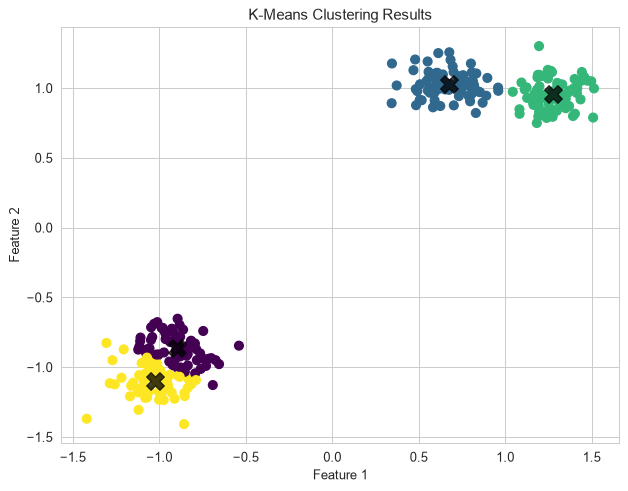

In [4]:
# Dataset X dari bagian sebelumnya (sudah di-scale) dipakai ulang
# Terapkan K-Means dengan k = 4
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

print('Jumlah titik per klaster :', np.bincount(y_kmeans))
print('Inertia (WCSS)           :', round(kmeans.inertia_, 3))
print('Jumlah iterasi           :', kmeans.n_iter_)
print('Pusat klaster (centroid):')
print(kmeans.cluster_centers_.round(3))

# Plot hasil klasterisasi
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.75, marker='X')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Interpretasi:**

- K-Means membagi 300 titik menjadi empat klaster yang ukurannya seimbang (**71, 77, 73, 79**) dan konvergen hanya dalam **4 iterasi** — tanda bahwa struktur data mudah ditemukan.
- Inertia akhir **7.30**: dibandingkan total variansi 600 (inertia untuk $K=1$), artinya sekitar 98.8% variansi data "dijelaskan" oleh pembagian ini.
- Koordinat centroid memperlihatkan dua pasangan: (−0.90, −0.87) & (−1.03, −1.10) di kiri-bawah, serta (0.68, 1.03) & (1.28, 0.96) di kanan-atas. Di kanan-atas K-Means memisahkan dua gumpalan yang memang tampak terpisah; di kiri-bawah K-Means terpaksa membelah satu gumpalan yang sebenarnya berisi dua blob yang berimpit dengan garis batas lurus, sehingga sebagian titik di sana tidak cocok dengan blob asalnya (lihat ARI di 10.5).

k = 1: inertia =   600.00
k = 2: inertia =    23.68
k = 3: inertia =     9.99
k = 4: inertia =     7.30
k = 5: inertia =     6.31
k = 6: inertia =     5.72
k = 7: inertia =     4.83
k = 8: inertia =     4.69
k = 9: inertia =     3.75


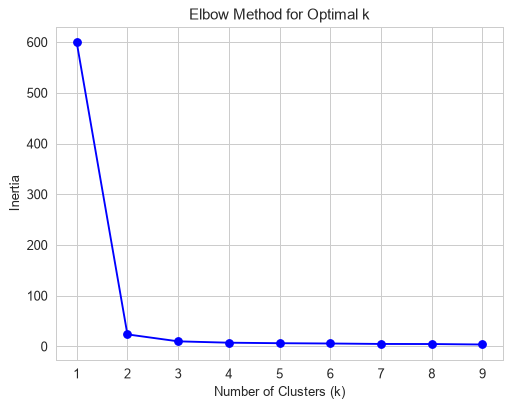

In [5]:
# Hitung dan plot inertia untuk k = 1..9 (elbow method)
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)

for k, w in zip(k_values, inertia):
    print(f'k = {k}: inertia = {w:8.2f}')

plt.plot(k_values, inertia, 'bo-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

*Tambahan (bukan bagian dari notebook asli):* elbow method sering ambigu, sehingga sel berikut menghitung **silhouette score** untuk setiap $K$ sebagai pembanding.

2    0.880
3    0.784
4    0.531
5    0.451
6    0.400
7    0.420
8    0.418
9    0.368
k dengan silhouette tertinggi: 2


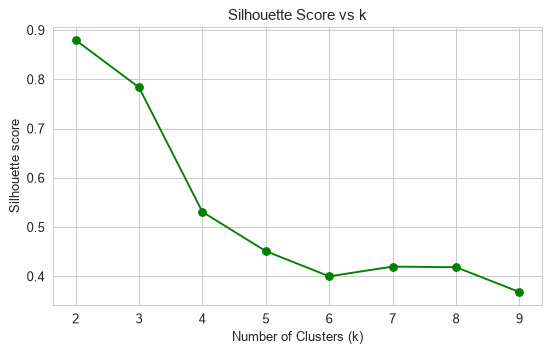

In [6]:
# Tambahan: silhouette score untuk k = 2..9 sebagai pembanding elbow method
sil = {}
for k in range(2, 10):
    labels_k = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    sil[k] = silhouette_score(X, labels_k)

sil_s = pd.Series(sil, name='silhouette')
print(sil_s.round(3).to_string())
print('k dengan silhouette tertinggi:', sil_s.idxmax())

plt.figure(figsize=(7, 4))
plt.plot(sil_s.index, sil_s.values, 'go-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette score')
plt.title('Silhouette Score vs k')
plt.show()

**Interpretasi:**

- Inertia anjlok dari **600** ($K=1$) ke **23.68** ($K=2$) — penurunan ≈96% — lalu ke 9.99 ($K=3$) dan 7.30 ($K=4$); setelahnya penurunan sangat landai (6.31, 5.72, …, 3.75). "Siku" paling tajam berada di **$K=2$**, dengan siku kedua yang jauh lebih lemah di sekitar $K=3$–4.
- Silhouette score juga paling tinggi pada **$K=2$ (0.880)**, kemudian 0.784 ($K=3$) dan 0.531 ($K=4$). Kedua kriteria sepakat bahwa pemisahan yang paling jelas adalah dua kelompok besar; $K=3$ (tiga gumpalan yang terlihat di 10.1) menjadi pilihan terbaik kedua.
- Pelajaran pentingnya: metrik internal mengukur **pemisahan geometris**, bukan "jumlah pusat pembangkit data". Karena dua pasang blob saling tumpang tindih, $K=4$ yang "benar" secara generatif justru tidak terlihat sebagai pilihan terbaik. Pemilihan $K$ sebaiknya juga mempertimbangkan pengetahuan domain dan tujuan analisis (misalnya apakah segmentasi halus 4 kelompok lebih berguna daripada 2).

## 10.3 Hierarchical Clustering

**Teori:**

**Dua pendekatan.** *Agglomerative* (bottom-up) dimulai dari $n$ klaster tunggal lalu berulang kali menggabungkan dua klaster yang paling dekat; *divisive* (top-down) dimulai dari satu klaster lalu memecahnya secara rekursif. scikit-learn hanya menyediakan versi agglomerative (`AgglomerativeClustering`); versi divisive bisa didekati misalnya dengan `BisectingKMeans`.

**Kriteria linkage** menentukan jarak antara dua klaster $A$ dan $B$:

| Linkage | Definisi jarak | Karakter |
|---|---|---|
| Single | $\min_{a\in A,b\in B} d(a,b)$ | Dapat mengikuti bentuk memanjang, tetapi rawan *chaining* (klaster "merantai") |
| Complete | $\max_{a\in A,b\in B} d(a,b)$ | Klaster kompak berdiameter kecil; sensitif outlier |
| Average (UPGMA) | $\frac{1}{|A||B|}\sum_{a,b} d(a,b)$ | Kompromi single–complete |
| Ward (default) | Kenaikan WCSS bila $A$ dan $B$ digabung: $\Delta(A,B)=\frac{|A||B|}{|A|+|B|}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2$ | Mirip K-Means: klaster bulat, ukuran seimbang; hanya untuk jarak Euclidean |

**Dendrogram** merekam seluruh riwayat penggabungan: sumbu vertikal menunjukkan jarak (tinggi) saat dua klaster digabung. Memotong pohon secara horizontal pada ketinggian $h$ menghasilkan partisi; jumlah klaster = jumlah garis vertikal yang terpotong. Celah vertikal yang **panjang** antara dua penggabungan berturut-turut menandakan klaster yang terpisah jelas — inilah dasar memilih jumlah klaster. Di scikit-learn kita dapat memberikan `n_clusters` **atau** `distance_threshold` (memotong pada ketinggian tertentu), tetapi tidak keduanya.

*Catatan:* SciPy (`linkage(method='ward')`) melaporkan tinggi Ward dalam skala $\sqrt{2\Delta}$, sehingga angkanya berbeda dengan inertia K-Means tetapi urutannya konsisten; `AgglomerativeClustering` memakai skala yang sama dengan SciPy untuk `distance_threshold`.

**Kelebihan dan kekurangan.** Tidak memerlukan $K$ di awal, memberi gambaran struktur bertingkat, dan bisa memakai berbagai metrik jarak. Namun kompleksitasnya $O(n^2)$ memori dan $O(n^2\log n)$–$O(n^3)$ waktu, sehingga kurang cocok untuk data sangat besar, dan penggabungan bersifat *greedy* (keputusan yang sudah dibuat tidak bisa dibatalkan).

Jumlah titik per klaster (agglomerative): [82 74 76 68]
ARI antara label K-Means dan agglomerative: 0.882


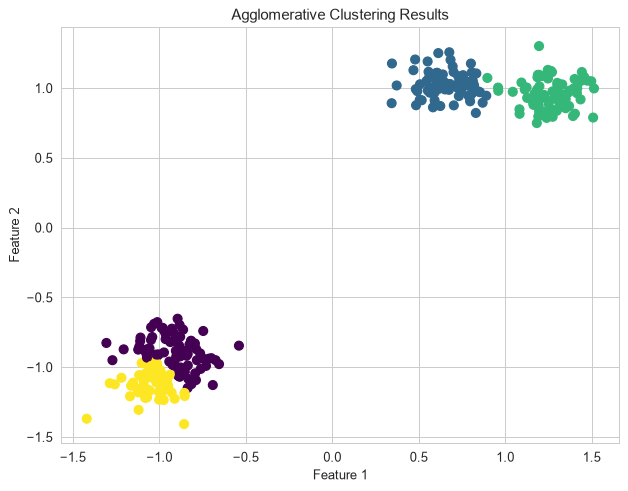

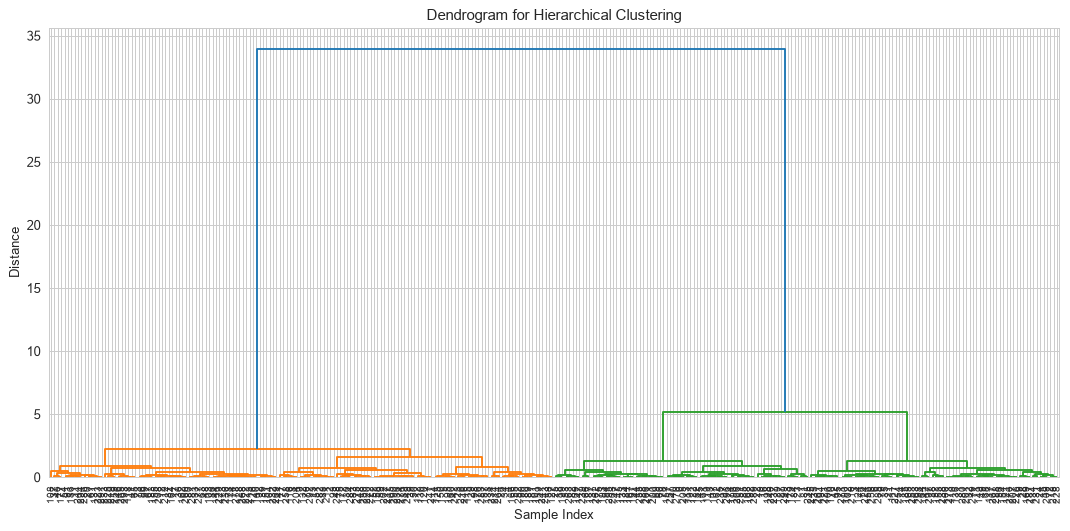

In [7]:
# Terapkan agglomerative clustering (default linkage='ward')
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

print('Jumlah titik per klaster (agglomerative):', np.bincount(y_agg))
print('ARI antara label K-Means dan agglomerative:',
      round(adjusted_rand_score(y_kmeans, y_agg), 3))

# Plot hasil klasterisasi
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Dendrogram dengan SciPy (metode Ward)
linked = linkage(X, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

*Tambahan (bukan bagian dari notebook asli):* membaca tinggi penggabungan dari matriks linkage, memotong pohon dengan `distance_threshold`, dan membandingkan keempat jenis linkage.

In [8]:
# Tambahan: jarak penggabungan (merge height) terakhir pada dendrogram Ward
# Kolom ke-3 matriks linkage = jarak saat dua klaster digabung
last_merges = linked[-6:, 2][::-1]
for i, h in enumerate(last_merges, start=1):
    print(f'Penggabungan ke-{i} dari atas: tinggi = {h:7.3f}  (menghasilkan {i} klaster di bawahnya)')

# Memotong pohon pada ketinggian tertentu (distance_threshold) alih-alih n_clusters
agg_thr = AgglomerativeClustering(n_clusters=None, distance_threshold=5.0)
labels_thr = agg_thr.fit_predict(X)
print('\nDengan distance_threshold=5.0 -> jumlah klaster:', agg_thr.n_clusters_)

# Perbandingan beberapa metode linkage pada data yang sama
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X)
    rows.append({'linkage': link,
                 'ukuran klaster': sorted(np.bincount(lab).tolist(), reverse=True),
                 'silhouette': round(silhouette_score(X, lab), 3),
                 'ARI vs K-Means': round(adjusted_rand_score(y_kmeans, lab), 3)})
display(pd.DataFrame(rows))

Penggabungan ke-1 dari atas: tinggi =  33.951  (menghasilkan 1 klaster di bawahnya)
Penggabungan ke-2 dari atas: tinggi =   5.208  (menghasilkan 2 klaster di bawahnya)
Penggabungan ke-3 dari atas: tinggi =   2.254  (menghasilkan 3 klaster di bawahnya)
Penggabungan ke-4 dari atas: tinggi =   1.577  (menghasilkan 4 klaster di bawahnya)
Penggabungan ke-5 dari atas: tinggi =   1.283  (menghasilkan 5 klaster di bawahnya)
Penggabungan ke-6 dari atas: tinggi =   1.252  (menghasilkan 6 klaster di bawahnya)

Dengan distance_threshold=5.0 -> jumlah klaster: 3


,linkage,ukuran klaster,silhouette,ARI vs K-Means
0,ward,"[82, 76, 74, 68]",0.516,0.882
1,complete,"[87, 76, 74, 63]",0.513,0.806
2,average,"[149, 77, 73, 1]",0.610,0.712
3,single,"[150, 148, 1, 1]",0.624,0.494


**Interpretasi:**

- Agglomerative (Ward) menghasilkan klaster berukuran **82, 74, 76, 68** dan sangat mirip dengan K-Means (**ARI = 0.882**). Perbedaan hanya terjadi pada titik-titik di perbatasan dua sub-blob yang saling tumpang tindih, karena kedua metode sama-sama meminimalkan variansi tetapi dengan prosedur berbeda (greedy vs iteratif).
- Dendrogram memperlihatkan dua cabang besar yang bergabung pada ketinggian **33.95**, jauh di atas penggabungan berikutnya (**5.21** dan **2.25**). Celah raksasa 5.2 → 34 menegaskan bahwa **2 klaster** adalah pemisahan paling alami; celah 2.25 → 5.21 menunjukkan bahwa 3 klaster juga cukup wajar, sedangkan dari 4 ke bawah (1.58, 1.28, 1.25) tingginya sudah rapat sehingga pemotongan menjadi semakin arbitrer.
- Dengan `distance_threshold=5.0` (memotong di antara 2.25 dan 5.21) diperoleh **3 klaster** — contoh bagaimana jumlah klaster ditentukan oleh ketinggian potong, bukan diberikan langsung.
- Perbandingan linkage: *ward* dan *complete* menghasilkan klaster seimbang. *Average* dan *single* justru menghasilkan klaster "sampah" berisi **1 titik** (ukuran [149, 77, 73, 1] dan [150, 148, 1, 1]): single linkage pada dasarnya menemukan 2 gumpalan besar lalu memisahkan dua outlier sebagai klaster sendiri (efek *chaining*). Ironisnya silhouette keduanya lebih tinggi (0.610 dan 0.624) karena silhouette menyukai pemisahan dua kelompok besar — bukti bahwa metrik internal harus dibaca bersama ukuran klaster dan visualisasi.

## 10.4 Density-Based Clustering dengan DBSCAN

**Teori:**

**Gagasan.** DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*, Ester dkk., 1996) mendefinisikan klaster sebagai wilayah **padat** yang dipisahkan oleh wilayah jarang. Dua parameter utama:

- `eps` ($\varepsilon$): radius lingkungan. Lingkungan titik $p$: $N_\varepsilon(p)=\{q : d(p,q)\le\varepsilon\}$.
- `min_samples`: jumlah minimum titik dalam $N_\varepsilon(p)$ (termasuk $p$ sendiri di scikit-learn) agar $p$ dianggap padat.

**Tiga jenis titik:**

1. **Core point:** $|N_\varepsilon(p)| \ge$ `min_samples`.
2. **Border point:** bukan core, tetapi berada dalam lingkungan $\varepsilon$ suatu core point.
3. **Noise point:** bukan keduanya; diberi label **−1**.

**Density-reachable dan density-connected.** Titik $q$ *directly density-reachable* dari core point $p$ bila $q\in N_\varepsilon(p)$; *density-reachable* bila ada rantai core point $p\to p_1\to\dots\to q$. Satu klaster = himpunan maksimal titik yang saling *density-connected*. Algoritmanya: ambil titik yang belum dikunjungi; bila core, kembangkan klaster lewat BFS/DFS ke seluruh tetangga yang dapat dijangkau; bila bukan core, tandai sementara sebagai noise (bisa berubah menjadi border bila nanti dijangkau core lain).

**Kelebihan:** tidak memerlukan $K$, dapat menemukan klaster **berbentuk sembarang** (non-convex), dan secara eksplisit mendeteksi **outlier**. **Kekurangan:** satu nilai `eps` global sulit menangani klaster dengan **kepadatan berbeda-beda** (lihat `HDBSCAN`/`OPTICS` untuk itu), sensitif terhadap skala fitur, dan kurang efektif di dimensi tinggi karena jarak menjadi kurang bermakna (*curse of dimensionality*). Kompleksitas rata-rata $O(n\log n)$ dengan struktur indeks (KD-tree/Ball-tree).

**Memilih `eps` dengan k-distance plot.** Untuk setiap titik hitung jarak ke tetangga terdekat ke-$k$ ($k\approx$ `min_samples`), urutkan naik, lalu plot. Titik di dalam klaster punya jarak k-NN kecil, sedangkan noise punya jarak besar; "siku" (lonjakan tajam) pada kurva adalah kandidat `eps` yang baik. Heuristik umum: `min_samples` $\ge p+1$, sering $2p$ untuk data 2D yang ber-*noise*.

In [9]:
# Dataset baru: dua "bulan sabit" dengan noise
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
print('Ukuran data:', X.shape)

Ukuran data: (300, 2)


Label dan jumlah titik:

 {-1: 4, 0: 150, 1: 146}
Jumlah klaster (tanpa noise): 2
Jumlah titik noise (label -1): 4
Jumlah core points: 290


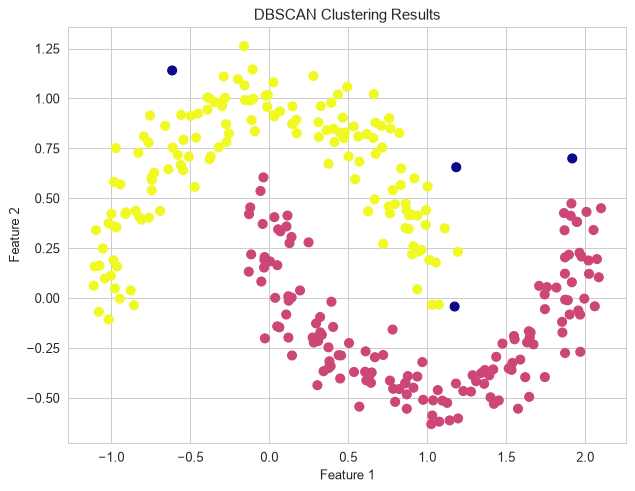

In [10]:
# Terapkan DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X)

labels_unik, jumlah = np.unique(y_db, return_counts=True)
print('Label dan jumlah titik:', dict(zip(labels_unik.tolist(), jumlah.tolist())))
print('Jumlah klaster (tanpa noise):', len(set(y_db)) - (1 if -1 in y_db else 0))
print('Jumlah titik noise (label -1):', int((y_db == -1).sum()))
print('Jumlah core points:', len(dbscan.core_sample_indices_))

# Plot hasil DBSCAN
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_db, cmap='plasma', s=50)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Persentil jarak k-NN (k=5): {50: 0.099, 75: 0.126, 90: 0.169, 95: 0.187, 99: 0.252}


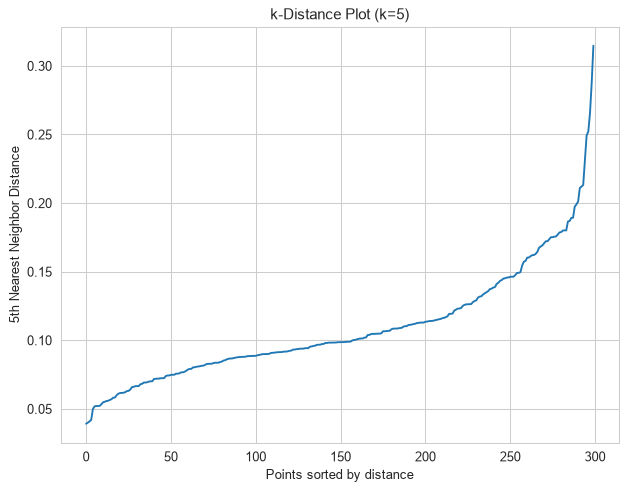

In [11]:
# k-distance plot untuk memilih eps
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
# Catatan: kneighbors(X) pada data latih menghitung titik itu sendiri sebagai tetangga pertama
# (jarak 0), sehingga kolom indeks 4 = tetangga terdekat ke-4 selain dirinya sendiri.
distances = np.sort(distances[:, 4])

print('Persentil jarak k-NN (k=5):',
      {p: round(float(np.percentile(distances, p)), 3) for p in [50, 75, 90, 95, 99]})

# Plot k-distance
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.title("k-Distance Plot (k=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()

*Tambahan (bukan bagian dari notebook asli):* sensitivitas jumlah klaster dan noise terhadap `eps`.

In [12]:
# Tambahan: sensitivitas DBSCAN terhadap eps (min_samples=5 tetap)
rows = []
for eps in [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    rows.append({'eps': eps,
                 'jumlah klaster': len(set(lab)) - (1 if -1 in lab else 0),
                 'jumlah noise': int((lab == -1).sum())})
display(pd.DataFrame(rows))

,eps,jumlah klaster,jumlah noise
0,0.05,4,279
1,0.10,18,62
2,0.15,4,12
3,0.20,2,4
4,0.30,1,0
5,0.50,1,0


**Interpretasi:**

- Dengan `eps=0.2` dan `min_samples=5`, DBSCAN menemukan tepat **2 klaster** (150 dan 146 titik) yang mengikuti kedua bentuk bulan sabit, ditambah **4 titik noise** (label −1, warna paling gelap pada plot). Sebanyak **290** dari 300 titik adalah core point — data cukup padat sehingga hampir semua titik berada di dalam klaster. Hal ini mustahil dicapai K-Means yang batasnya selalu lurus (lihat Exercise 2).
- Pada k-distance plot, sebagian besar titik memiliki jarak ke tetangga ke-5 di bawah ≈0.17 (persentil 90% = **0.169**, persentil 95% = **0.187**), lalu kurva melonjak tajam di ujung kanan (persentil 99% = 0.252). Siku berada di kisaran **0.17–0.25**, sehingga pilihan `eps=0.2` memang masuk akal.
- Tabel sensitivitas memperlihatkan betapa kritisnya `eps`: terlalu kecil (0.05) → hampir semua titik (279) dianggap noise; 0.10 → data terpecah menjadi **18** klaster kecil; 0.15 → 4 klaster dengan 12 noise; **0.20 → 2 klaster dengan 4 noise (ideal)**; sedangkan ≥0.30 → kedua bulan sabit tersambung menjadi **1** klaster karena jembatan antar bulan sudah masuk radius. Rentang nilai yang "benar" cukup sempit, sehingga k-distance plot sangat membantu.

## 10.5 Metrik Evaluasi Klaster

**Teori:**

Evaluasi clustering terbagi dua: **metrik internal** (hanya memakai $X$ dan label klaster) dan **metrik eksternal** (membandingkan dengan label sebenarnya, bila tersedia — misalnya pada data benchmark).

**1. Silhouette coefficient (internal).** Untuk titik $i$ di klaster $C_I$:

$$
a(i)=\frac{1}{|C_I|-1}\sum_{j\in C_I, j\ne i} d(i,j), \qquad b(i)=\min_{J\ne I}\frac{1}{|C_J|}\sum_{j\in C_J} d(i,j), \qquad s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}} .
$$

$a(i)$ = kohesi (jarak rata-rata ke klasternya sendiri), $b(i)$ = jarak rata-rata ke klaster tetangga terdekat. $s(i)\in[-1,1]$: mendekati 1 berarti titik jauh lebih dekat ke klasternya sendiri, ≈0 berarti berada di perbatasan, negatif berarti kemungkinan salah klaster. **Silhouette score** = rata-rata $s(i)$; semakin besar semakin baik. Biayanya $O(n^2)$, dan metrik ini cenderung menyukai klaster cembung (sehingga kurang adil untuk hasil DBSCAN berbentuk aneh).

**2. Davies–Bouldin index (internal).** Dengan $s_k$ = jarak rata-rata anggota ke centroid klaster $k$ dan $d_{kl}=\lVert\boldsymbol\mu_k-\boldsymbol\mu_l\rVert$:

$$
DB = \frac{1}{K}\sum_{k=1}^{K}\max_{l\ne k}\frac{s_k+s_l}{d_{kl}} .
$$

Rasio "sebaran gabungan / jarak antar pusat" untuk pasangan klaster yang paling mirip. Nilai minimum 0; **semakin kecil semakin baik**. Klaster yang tumpang tindih mendapat penalti besar.

**3. Calinski–Harabasz index / variance ratio criterion (internal).** Dengan $B$ = dispersi antar klaster dan $W$ = dispersi dalam klaster:

$$
CH = \frac{\operatorname{tr}(B)/(K-1)}{\operatorname{tr}(W)/(n-K)}, \quad \operatorname{tr}(B)=\sum_k |C_k|\,\lVert\boldsymbol\mu_k-\bar{\mathbf x}\rVert^2,\quad \operatorname{tr}(W)=\sum_k\sum_{\mathbf x_i\in C_k}\lVert\mathbf x_i-\boldsymbol\mu_k\rVert^2 .
$$

Analog dengan statistik F pada ANOVA; **semakin besar semakin baik**; sangat cepat dihitung.

**4. Adjusted Rand Index (eksternal).** Rand Index menghitung proporsi pasangan titik yang diperlakukan konsisten oleh dua partisi (sama-sama satu klaster atau sama-sama beda klaster). ARI mengoreksinya terhadap peluang acak:

$$
ARI = \frac{RI - \mathbb E[RI]}{\max(RI) - \mathbb E[RI]} ,
$$

sehingga partisi acak bernilai ≈0, kesepakatan sempurna = 1 (bisa sedikit negatif). ARI **tidak peduli nama/nomor label** (permutasi label tidak berpengaruh), sehingga cocok untuk membandingkan hasil clustering dengan kelas asli. Alternatif eksternal lain: *Normalized/Adjusted Mutual Information*, *homogeneity/completeness/V-measure*, *Fowlkes–Mallows*.

**Pitfall:** metrik internal mengukur kriteria geometris tertentu yang belum tentu sama dengan "kebenaran" atau kegunaan bisnis; gunakan beberapa metrik sekaligus, ditambah visualisasi dan pengetahuan domain.

In [13]:
# Dataset berlabel (y_true) untuk keperluan evaluasi
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)

# Latih KMeans untuk dievaluasi
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)
print('Ukuran klaster:', np.bincount(y_kmeans))

Ukuran klaster: [71 77 73 79]


In [14]:
# Silhouette score
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score: {sil_score:.3f}")

# Davies-Bouldin index
db_index = davies_bouldin_score(X, y_kmeans)
print(f"Davies-Bouldin Index: {db_index:.3f}")

# (Opsional) Adjusted Rand index bila ground truth diketahui
ari = adjusted_rand_score(y_true, y_kmeans)
print(f"Adjusted Rand Index: {ari:.3f}")

# Bagian "There's more": Calinski-Harabasz index
ch = calinski_harabasz_score(X, y_kmeans)
print(f"Calinski-Harabasz Index: {ch:.1f}")

Silhouette Score: 0.534
Davies-Bouldin Index: 0.702
Adjusted Rand Index: 0.814
Calinski-Harabasz Index: 8670.8


*Tambahan (bukan bagian dari notebook asli):* membandingkan keempat metrik untuk berbagai nilai $K$, serta silhouette per titik.

In [15]:
# Tambahan: bagaimana metrik berubah bila k salah pilih?
rows = []
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    rows.append({'k': k,
                 'silhouette (maks)': silhouette_score(X, lab),
                 'Davies-Bouldin (min)': davies_bouldin_score(X, lab),
                 'Calinski-Harabasz (maks)': calinski_harabasz_score(X, lab),
                 'ARI vs y_true': adjusted_rand_score(y_true, lab)})
display(pd.DataFrame(rows).set_index('k').round(3))

# Silhouette per titik untuk k=4: berapa titik bernilai negatif (kemungkinan salah klaster)?
s_i = silhouette_samples(X, y_kmeans)
print('Silhouette per titik: min = %.3f, median = %.3f, jumlah negatif = %d'
      % (s_i.min(), np.median(s_i), (s_i < 0).sum()))

,silhouette (maks),Davies-Bouldin (min),Calinski-Harabasz (maks),ARI vs y_true
k,,,,
2,0.887,0.169,8523.616,0.497
3,0.768,0.390,8819.986,0.697
4,0.534,0.702,8670.779,0.814
5,0.446,0.879,7294.189,0.729
6,0.391,0.966,6461.760,0.633
7,0.400,0.942,6172.063,0.581


Silhouette per titik: min = -0.040, median = 0.575, jumlah negatif = 2


**Interpretasi:**

- Catatan: pada resep ini data **tidak** distandardisasi (berbeda dengan 10.1), sehingga angka berada dalam satuan asli, tetapi klaster yang ditemukan identik (ukuran **71, 77, 73, 79**).
- **Silhouette = 0.534**: klaster cukup terstruktur tetapi tidak sangat terpisah — rata-rata titik hanya ≈ setengah jalan lebih dekat ke klasternya sendiri dibanding klaster tetangga. **Davies–Bouldin = 0.702** (cukup rendah, baik) dan **Calinski–Harabasz ≈ 8671** (sangat tinggi karena jarak antar dua gumpalan besar sangat jauh dibanding sebaran di dalamnya).
- **ARI = 0.814** terhadap label pembangkit: kesepakatan tinggi tetapi tidak sempurna, sebab dua pasangan blob tumpang tindih sehingga sebagian titik "milik" blob A secara generatif lebih dekat ke centroid blob B — kesalahan yang tidak bisa dihindari oleh algoritma berbasis jarak.
- Tabel per-$K$ memperlihatkan bahwa metrik internal **tidak sepakat** dengan kebenaran: silhouette (0.887) dan Davies–Bouldin (0.169) terbaik pada $K=2$, Calinski–Harabasz terbaik pada $K=3$ (≈8820, sedikit di atas 8671 pada $K=4$), sedangkan ARI terhadap label asli justru tertinggi pada **$K=4$ (0.814)**. Jadi metrik internal menilai "seberapa jelas pemisahan", bukan "seberapa sesuai dengan proses pembangkit data".
- Silhouette per titik untuk $K=4$: median 0.575, minimum −0.040, dan hanya **2 titik** yang bernilai negatif — titik-titik di perbatasan sub-blob yang mungkin salah klaster.

## 10.6 Memilih Algoritma Clustering yang Tepat

**Teori:**

Tidak ada algoritma clustering yang terbaik untuk semua data (*no free lunch*). Setiap algoritma membawa **asumsi** tentang apa itu "klaster":

| Kriteria | K-Means | Agglomerative | DBSCAN | Spectral | GMM |
|---|---|---|---|---|---|
| Perlu jumlah klaster? | Ya ($K$) | Ya, atau `distance_threshold` | Tidak (perlu `eps`, `min_samples`) | Ya | Ya (pilih dengan BIC/AIC) |
| Bentuk klaster | Cembung, bulat | Tergantung linkage | Sembarang | Sembarang (berbasis graf) | Elips |
| Menangani noise/outlier | Tidak | Tidak | **Ya** (label −1) | Tidak | Sebagian (probabilitas rendah) |
| Skalabilitas | Sangat baik $O(nKp)$ | Buruk $O(n^2)$ | Baik $O(n\log n)$ | Buruk (eigen-dekomposisi) | Sedang |
| Parameter sensitif | $K$, inisialisasi | linkage, potongan | `eps`, `min_samples` | affinity, `n_neighbors`/`gamma` | `n_components`, `covariance_type` |

**Dimensi tinggi.** Pada $p$ besar, jarak antar titik cenderung seragam (*distance concentration*), sehingga semua algoritma berbasis jarak/kepadatan melemah. Praktik yang umum: standardisasi → reduksi dimensi (PCA, atau UMAP/t-SNE untuk visualisasi) → clustering.

**Tiga dataset uji klasik** dari scikit-learn: **blobs** (klaster Gaussian bulat; ideal untuk K-Means/GMM), **moons** (dua bulan sabit yang saling mengait; non-convex), dan **circles** (dua cincin konsentris; klaster dalam sepenuhnya dikelilingi klaster luar — mustahil dipisahkan dengan batas linear).

In [16]:
# Membuat dan men-scale tiga jenis dataset
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons = StandardScaler().fit_transform(X_moons)
X_circles = StandardScaler().fit_transform(X_circles)

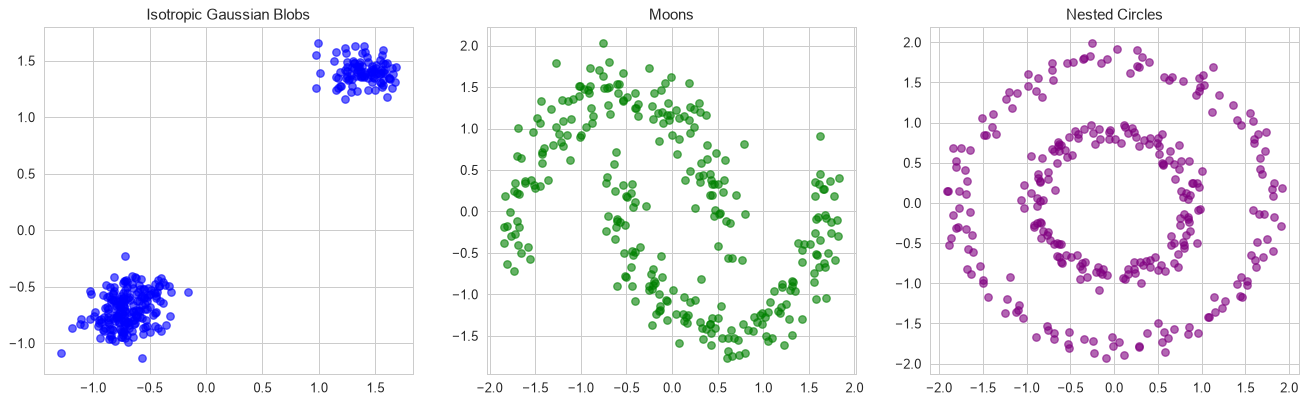

In [17]:
# Visualisasi ketiga dataset
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c='blue', alpha=0.6)
axs[0].set_title("Isotropic Gaussian Blobs")
axs[1].scatter(X_moons[:, 0], X_moons[:, 1], c='green', alpha=0.6)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1], c='purple', alpha=0.6)
axs[2].set_title("Nested Circles")
plt.show()

*Tambahan (bukan bagian dari notebook asli):* notebook asli hanya memvisualisasikan ketiga dataset. Sel berikut menjalankan empat algoritma pada ketiganya dan menghitung ARI terhadap label pembangkit, agar panduan di atas terlihat secara empiris.

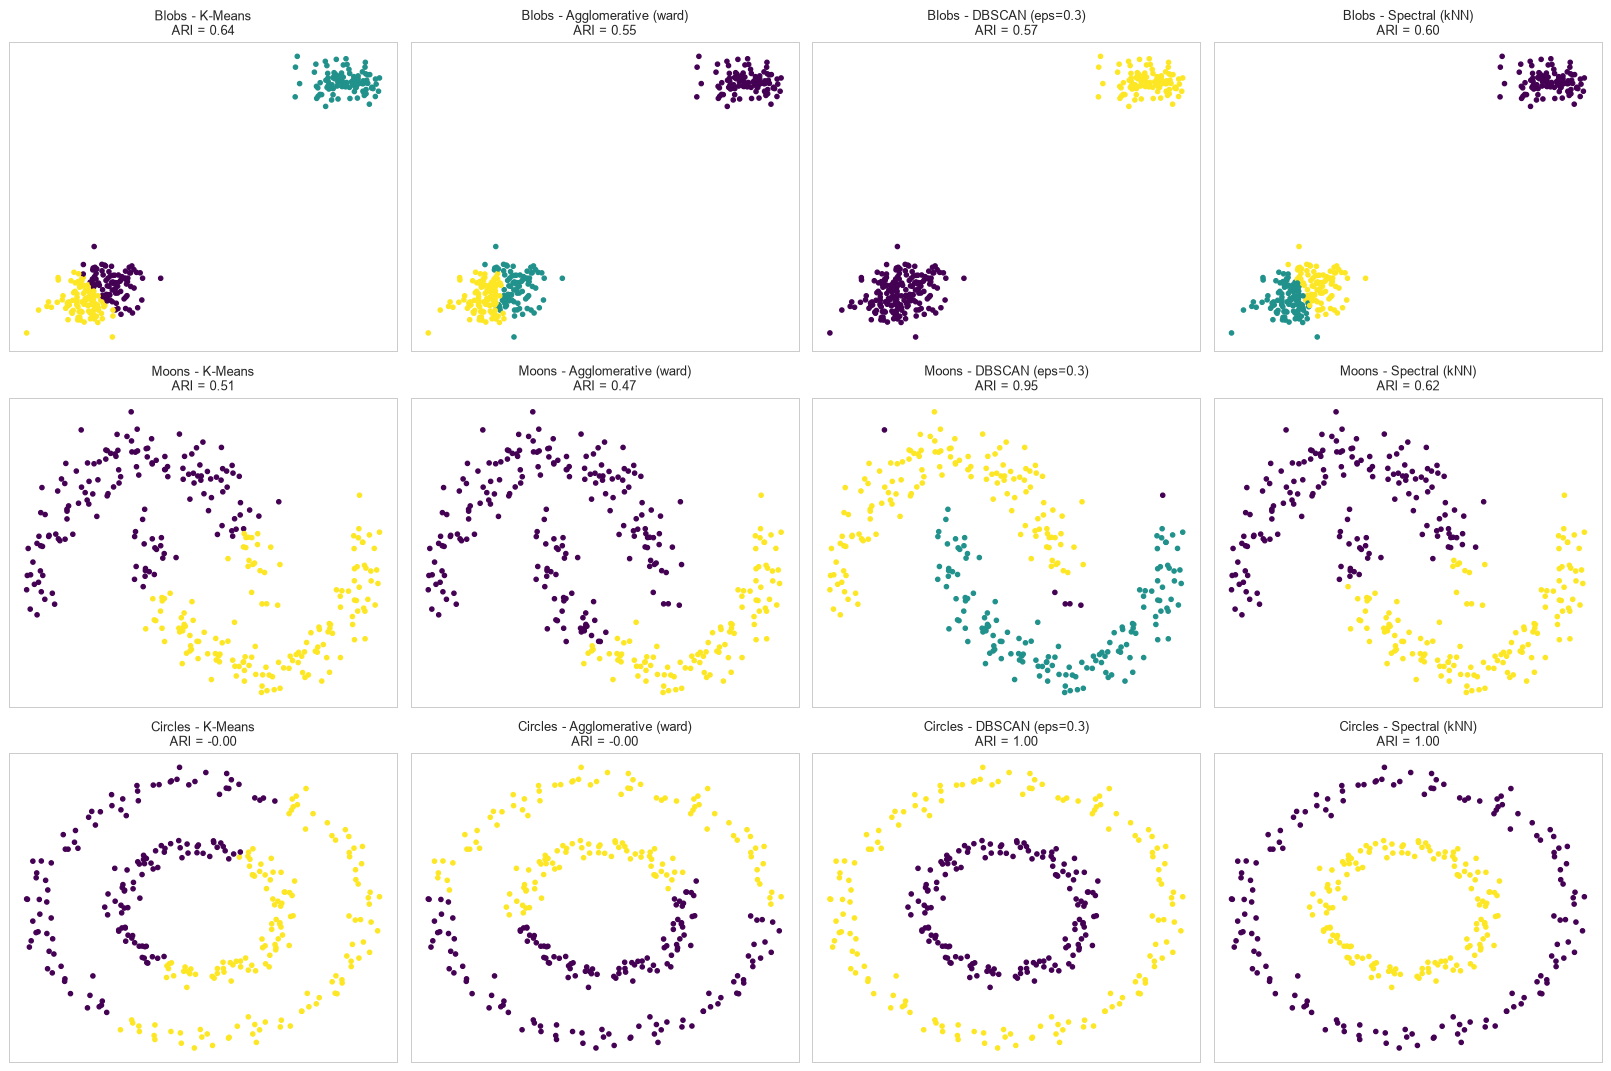

,Blobs,Moons,Circles
K-Means,0.644,0.507,-0.003
Agglomerative (ward),0.552,0.470,-0.003
DBSCAN (eps=0.3),0.570,0.948,1.000
Spectral (kNN),0.599,0.618,1.000


In [18]:
# Tambahan: bandingkan 4 algoritma pada 3 dataset sekaligus (label asli dipakai untuk ARI)
_, y_blobs = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
_, y_moons = make_moons(n_samples=300, noise=0.1, random_state=2024)
_, y_circles = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

datasets = {'Blobs': (X_blobs, y_blobs, 3),
            'Moons': (X_moons, y_moons, 2),
            'Circles': (X_circles, y_circles, 2)}

def make_models(k):
    return {'K-Means': KMeans(n_clusters=k, random_state=2024),
            'Agglomerative (ward)': AgglomerativeClustering(n_clusters=k),
            'DBSCAN (eps=0.3)': DBSCAN(eps=0.3, min_samples=5),
            'Spectral (kNN)': SpectralClustering(n_clusters=k, affinity='nearest_neighbors',
                                                 random_state=2024)}

fig, axs = plt.subplots(3, 4, figsize=(18, 12))
ari_table = {}
# Spectral (kNN) bisa memberi peringatan 'Graph is not fully connected' -> disembunyikan agar rapi
warnings.filterwarnings('ignore', message='Graph is not fully connected')
for i, (dname, (Xd, yd, k)) in enumerate(datasets.items()):
    for j, (mname, model) in enumerate(make_models(k).items()):
        lab = model.fit_predict(Xd)
        ari_table.setdefault(mname, {})[dname] = adjusted_rand_score(yd, lab)
        axs[i, j].scatter(Xd[:, 0], Xd[:, 1], c=lab, cmap='viridis', s=12)
        axs[i, j].set_title(f'{dname} - {mname}\nARI = {ari_table[mname][dname]:.2f}', fontsize=10)
        axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
plt.tight_layout()
plt.show()

display(pd.DataFrame(ari_table).T.round(3))

**Interpretasi:**

- **Blobs:** dari tiga pusat, dua blob kembali jatuh berdekatan dan saling bertumpuk (salah satu gumpalan tampak memanjang), sehingga tidak ada metode yang sempurna: K-Means terbaik (**ARI 0.644**), disusul Spectral (0.599), DBSCAN (0.570) dan Ward (0.552). DBSCAN menggabungkan dua blob yang bersentuhan menjadi satu klaster (200 + 100 titik), wajar karena di antara keduanya tidak ada wilayah jarang.
- **Moons:** K-Means (**0.507**) dan Ward (0.470) memotong kedua bulan sabit dengan garis lurus. DBSCAN (`eps=0.3` pada data terstandardisasi) hampir sempurna (**0.948**). Spectral dengan graf kNN default (10 tetangga) hanya 0.618 karena noise 0.1 membuat ujung-ujung bulan sabit tersambung di graf; pada data dengan noise lebih kecil (10.7) Spectral mencapai ARI 1.0.
- **Circles:** K-Means dan Ward gagal total (**ARI ≈ −0.003**, setara tebakan acak) karena cincin dalam dan luar memiliki pusat yang sama. DBSCAN dan Spectral memisahkan keduanya dengan **sempurna (ARI 1.000)**.
- Kesimpulannya sesuai teori: metode berbasis centroid/variansi cocok untuk klaster bulat, sedangkan metode berbasis kepadatan/graf unggul untuk bentuk non-convex. Selalu plot data mentah (atau proyeksinya) sebelum memilih algoritma.

## 10.7 Teknik Clustering Lanjutan: Spectral Clustering & Gaussian Mixture Models

**Teori:**

### Spectral Clustering

1. **Bangun graf kemiripan** dengan matriks afinitas $W$. Pilihan `affinity`: `'rbf'` (default) $W_{ij}=\exp(-\gamma\lVert\mathbf x_i-\mathbf x_j\rVert^2)$, atau `'nearest_neighbors'` ($W_{ij}=1$ bila $j$ termasuk `n_neighbors` tetangga terdekat $i$, disimetrikan).
2. **Hitung Laplacian graf** $L = D - W$ dengan $D=\operatorname{diag}(\sum_j W_{ij})$; scikit-learn memakai versi ternormalisasi $L_{\text{sym}} = I - D^{-1/2} W D^{-1/2}$.
3. **Spectral embedding:** ambil $K$ eigenvektor dengan eigenvalue terkecil dari $L$ — ini memetakan setiap titik ke ruang berdimensi $K$.
4. **Klasterisasi di ruang embedding** dengan K-Means (default `assign_labels='kmeans'`, alternatif `'discretize'`/`'cluster_qr'`).

Intuisi: spectral clustering adalah relaksasi kontinu dari masalah **graph cut** (*normalized cut*) — mencari pemotongan graf yang memutus sesedikit mungkin sisi berbobot sambil menjaga ukuran tiap bagian seimbang. Karena hanya konektivitas graf yang penting, bentuk geometris klaster boleh sembarang (bulan sabit, cincin). Jika graf terdiri dari $K$ komponen yang benar-benar terpisah, eigenvalue 0 muncul $K$ kali dan eigenvektornya adalah indikator komponen. Kekurangannya: eigen-dekomposisi matriks $n\times n$ mahal untuk $n$ besar, hasil sensitif terhadap `gamma`/`n_neighbors`, dan tidak ada metode `predict` untuk data baru.

### Gaussian Mixture Models (GMM)

GMM mengasumsikan data berasal dari campuran $K$ distribusi normal:

$$
p(\mathbf x) = \sum_{k=1}^{K} \pi_k\, \mathcal N(\mathbf x \mid \boldsymbol\mu_k, \Sigma_k), \qquad \pi_k\ge 0,\ \sum_k\pi_k = 1 .
$$

Parameter diestimasi dengan **algoritma Expectation–Maximization (EM)** yang memaksimalkan log-likelihood $\sum_i \log p(\mathbf x_i)$:

- **E-step:** hitung *responsibility* (probabilitas posterior keanggotaan) $\gamma_{ik} = \dfrac{\pi_k\,\mathcal N(\mathbf x_i\mid\boldsymbol\mu_k,\Sigma_k)}{\sum_{l}\pi_l\,\mathcal N(\mathbf x_i\mid\boldsymbol\mu_l,\Sigma_l)}$.
- **M-step:** perbarui $N_k=\sum_i\gamma_{ik}$, $\pi_k = N_k/n$, $\boldsymbol\mu_k = \frac{1}{N_k}\sum_i\gamma_{ik}\mathbf x_i$, $\Sigma_k = \frac{1}{N_k}\sum_i\gamma_{ik}(\mathbf x_i-\boldsymbol\mu_k)(\mathbf x_i-\boldsymbol\mu_k)^\top$.

Ini adalah **soft clustering**: `predict_proba` mengembalikan $\gamma_{ik}$, sedangkan `predict` memilih $\arg\max_k \gamma_{ik}$. K-Means dapat dipandang sebagai kasus khusus GMM dengan kovarians $\sigma^2 I$ yang sama untuk semua komponen dan $\sigma\to 0$ (penugasan keras). Parameter `covariance_type` (`'full'`, `'tied'`, `'diag'`, `'spherical'`) mengatur fleksibilitas bentuk elips. Jumlah komponen dapat dipilih dengan kriteria informasi $\text{BIC} = -2\log\hat L + m\log n$ ($m$ = jumlah parameter; semakin kecil semakin baik). Karena setiap komponen berbentuk elips, GMM tetap kesulitan dengan klaster non-convex seperti bulan sabit.

In [19]:
# Dataset dengan struktur kompleks (moons, noise kecil)
X, y_moons_true = make_moons(n_samples=300, noise=0.05, random_state=2024)
X = StandardScaler().fit_transform(X)

ARI Spectral vs label asli: 1.0
ARI GMM      vs label asli: 0.526


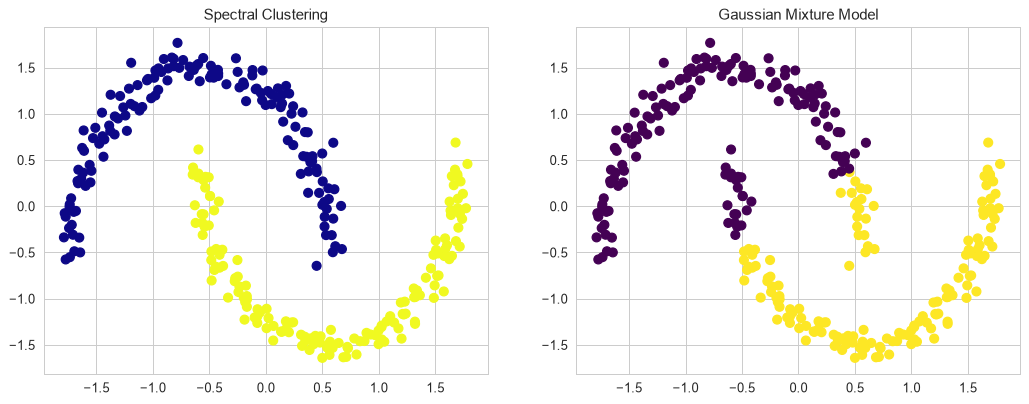

In [20]:
# Spectral Clustering
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X)

# Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X)

print('ARI Spectral vs label asli:', round(adjusted_rand_score(y_moons_true, y_spectral), 3))
print('ARI GMM      vs label asli:', round(adjusted_rand_score(y_moons_true, y_gmm), 3))

# Visualisasi kedua hasil
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_spectral, cmap='plasma', s=50)
ax1.set_title("Spectral Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_gmm, cmap='viridis', s=50)
ax2.set_title("Gaussian Mixture Model")

plt.show()

*Tambahan (bagian "There's more" pada buku):* probabilitas keanggotaan GMM (`predict_proba`) dan pemilihan jumlah komponen dengan BIC.

Bobot campuran (weights_)  : [0.501 0.499]
Rata-rata mean tiap komponen:
[[-0.724  0.779]
 [ 0.726 -0.781]]
Titik dengan keyakinan < 0.9: 40 dari 300
Log-likelihood rata-rata   : -2.557


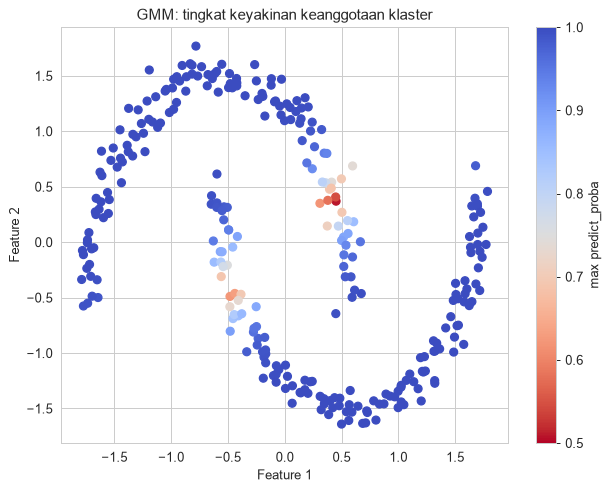

BIC per jumlah komponen: {1: 1665.9, 2: 1597.1, 3: 1516.8, 4: 1318.8, 5: 1276.1, 6: 1194.6, 7: 1085.6, 8: 1073.7}
Jumlah komponen dengan BIC terkecil: 8


In [21]:
# Tambahan ("There's more"): probabilitas keanggotaan GMM via predict_proba
proba = gmm.predict_proba(X)
max_p = proba.max(axis=1)
print('Bobot campuran (weights_)  :', gmm.weights_.round(3))
print('Rata-rata mean tiap komponen:')
print(gmm.means_.round(3))
print('Titik dengan keyakinan < 0.9:', int((max_p < 0.9).sum()), 'dari', len(X))
print('Log-likelihood rata-rata   :', round(gmm.score(X), 3))

plt.figure(figsize=(8, 6))
sc = plt.scatter(X[:, 0], X[:, 1], c=max_p, cmap='coolwarm_r', s=40, vmin=0.5, vmax=1)
plt.colorbar(sc, label='max predict_proba')
plt.title('GMM: tingkat keyakinan keanggotaan klaster')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()

# Pemilihan jumlah komponen GMM dengan BIC (lebih kecil lebih baik)
bic = {k: GaussianMixture(n_components=k, random_state=2024).fit(X).bic(X) for k in range(1, 9)}
print('BIC per jumlah komponen:', {k: round(v, 1) for k, v in bic.items()})
print('Jumlah komponen dengan BIC terkecil:', min(bic, key=bic.get))

**Interpretasi:**

- **Spectral Clustering** memisahkan kedua bulan sabit dengan **sempurna (ARI = 1.0)**: dengan noise kecil (0.05), graf kNN hanya menghubungkan titik-titik di sepanjang tiap bulan sabit, sehingga pemotongan graf yang paling "murah" persis di antara kedua bulan.
- **GMM** dengan 2 komponen hanya mencapai **ARI 0.526**: kedua komponen Gaussian berpusat di (−0.72, 0.78) dan (0.73, −0.78) dengan bobot ≈0.50 masing-masing, sehingga batas keputusannya kira-kira garis diagonal yang memotong ujung setiap bulan sabit — mirip kegagalan K-Means. Sebuah elips tidak dapat menggambarkan bentuk lengkung.
- Plot tingkat keyakinan menunjukkan bahwa sebagian besar titik ditetapkan dengan probabilitas tinggi, tetapi **40 dari 300** titik memiliki `max predict_proba` < 0.9 — terkonsentrasi di sekitar batas antar komponen. Informasi ketidakpastian seperti ini adalah kelebihan utama soft clustering.
- BIC terus menurun hingga **8 komponen** (1665.9 → 1073.7): untuk meniru bentuk bulan sabit, GMM membutuhkan banyak elips kecil yang berderet. Artinya jumlah komponen GMM optimal menurut BIC belum tentu sama dengan jumlah klaster yang bermakna; komponen-komponen tersebut perlu digabung lagi (misalnya secara hierarkis) bila ingin memperoleh 2 kelompok.

## Latihan

Bagian ini mereproduksi tiga latihan di akhir chapter (*Practical Exercises with Clustering Models*) beserta solusinya dari notebook *Exercise Solutions*. Latihan memakai dataset nyata bawaan scikit-learn (Iris dan Wine) serta data sintetis moons. Beberapa baris evaluasi tambahan (ARI, tabel kontingensi) ditambahkan agar hasil lebih mudah ditafsirkan.

### Exercise 1: Clustering dengan K-Means pada Dataset Iris

**Teori singkat:** Dataset Iris berisi 150 bunga dari 3 spesies (*setosa*, *versicolor*, *virginica*) dengan 4 fitur (panjang/lebar sepal dan petal, dalam cm). Label spesies **tidak** dipakai untuk melatih K-Means; label hanya dipakai setelahnya untuk evaluasi eksternal (ARI). Untuk visualisasi, data 4 dimensi diproyeksikan ke 2 komponen utama dengan **PCA** (proyeksi ke arah variansi terbesar). Keempat fitur sudah berskala serupa (cm), sehingga solusi buku tidak melakukan standardisasi.

Silhouette Score: 0.553
Adjusted Rand Index: 0.730



klaster,0,1,2
spesies,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


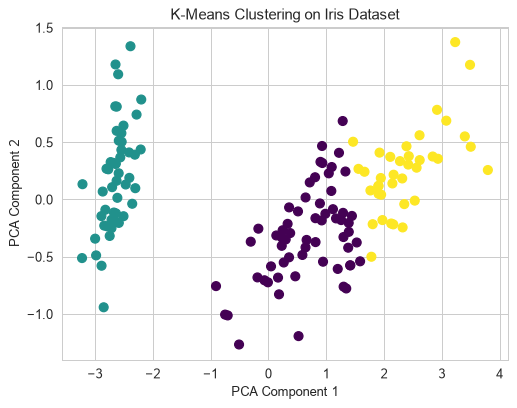

In [22]:
# Exercise 1: K-Means pada Iris
iris = load_iris()
X = iris.data
y_true = iris.target

# Membuat dan melatih model KMeans
kmeans = KMeans(n_clusters=3, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Evaluasi klasterisasi
sil_score = silhouette_score(X, y_kmeans)
ari = adjusted_rand_score(y_true, y_kmeans)

print(f"Silhouette Score: {sil_score:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")

# Tambahan: tabel kontingensi klaster vs spesies asli
print()
display(pd.crosstab(pd.Series(iris.target_names[y_true], name='spesies'),
                    pd.Series(y_kmeans, name='klaster')))

# Visualisasi penugasan klaster (proyeksi PCA)
X_pca = PCA(n_components=2).fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', s=50)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

**Interpretasi:**

- **Silhouette 0.553** dan **ARI 0.730**: klasterisasi cukup baik, tetapi tidak sempurna.
- Tabel kontingensi menjelaskan penyebabnya: semua **50 setosa** terkumpul sempurna dalam satu klaster (setosa terpisah jauh dari dua spesies lain, terutama pada ukuran petal). Sebaliknya, *versicolor* dan *virginica* saling tumpang tindih: 48 versicolor + **14 virginica** masuk klaster yang sama, sementara 2 versicolor masuk klaster virginica. Total 16 dari 150 bunga (≈10.7%) "salah" kelompok bila dibandingkan spesies.
- Pada proyeksi PCA, klaster setosa terpisah jelas di sisi kiri, sedangkan dua klaster lainnya bersebelahan dengan batas lurus — batas Voronoi K-Means tidak dapat mengikuti tumpang tindih alami kedua spesies tersebut.

### Exercise 2: Membandingkan DBSCAN dan K-Means pada Data Moons

**Teori singkat:** Latihan ini menguji klaim bahwa DBSCAN unggul pada klaster **non-convex**. Data moons distandardisasi terlebih dahulu sehingga radius `eps=0.3` diukur dalam satuan simpangan baku (berbeda dengan 10.4 yang memakai data mentah dan `eps=0.2`). K-Means diberi jumlah klaster yang "benar" ($K=2$) — jadi kegagalannya murni akibat asumsi bentuk, bukan salah memilih $K$.

ARI K-Means: 0.507
ARI DBSCAN : 0.948
DBSCAN -> klaster: 2 | noise: 6


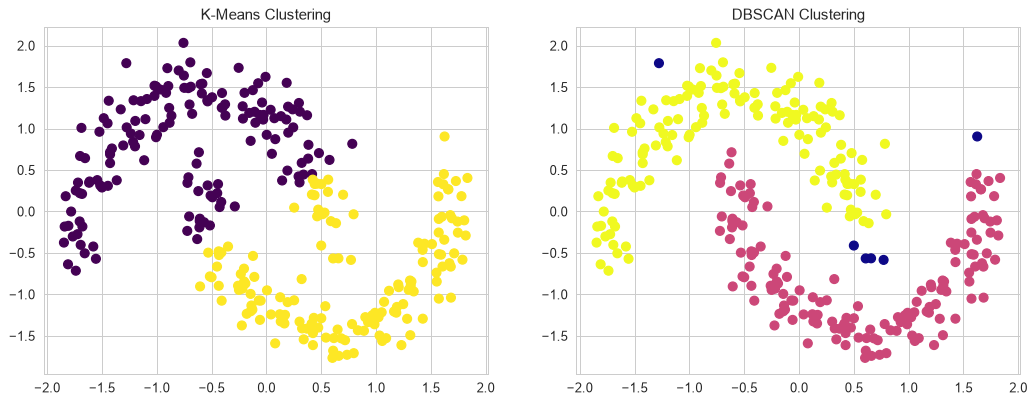

In [23]:
# Exercise 2: DBSCAN vs K-Means pada data moons
X, y_true = make_moons(n_samples=300, noise=0.1, random_state=2024)
X = StandardScaler().fit_transform(X)

# Terapkan KMeans dan DBSCAN
kmeans = KMeans(n_clusters=2, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

print('ARI K-Means:', round(adjusted_rand_score(y_true, y_kmeans), 3))
print('ARI DBSCAN :', round(adjusted_rand_score(y_true, y_dbscan), 3))
print('DBSCAN -> klaster:', len(set(y_dbscan)) - (1 if -1 in y_dbscan else 0),
      '| noise:', int((y_dbscan == -1).sum()))

# Visualisasi hasil
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis', s=50)
ax1.set_title("K-Means Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_dbscan, cmap='plasma', s=50)
ax2.set_title("DBSCAN Clustering")

plt.show()

**Interpretasi:**

- **K-Means: ARI 0.507** — meskipun diberi $K=2$ yang benar, K-Means memotong data dengan satu garis lurus sehingga ujung setiap bulan sabit masuk ke klaster yang salah.
- **DBSCAN: ARI 0.948** dengan **2 klaster** dan hanya **6 titik noise**: mengikuti lengkungan kedua bulan sabit hampir sempurna; selisih dari ARI 1.0 hanya berasal dari titik-titik noise yang tidak masuk klaster mana pun.
- Ini menegaskan pelajaran 10.6: untuk bentuk non-convex, algoritma berbasis kepadatan jauh lebih tepat daripada algoritma berbasis centroid.

### Exercise 3: Clustering Data Berdimensi Tinggi dengan PCA + GMM

**Teori singkat:** Dataset Wine berisi 178 sampel anggur dari 3 kultivar dengan **13** fitur kimia berskala sangat berbeda (misalnya *proline* ratusan–ribuan, *hue* ≈1). Alurnya: **standardisasi** (wajib, karena PCA dan GMM sensitif skala) → **PCA** 13 → 2 dimensi (mengurangi noise dan *curse of dimensionality*, serta memungkinkan visualisasi) → **GMM** 3 komponen yang memberi klaster elips dan probabilitas keanggotaan.

Explained variance ratio PC1, PC2: [0.362 0.192] | total: 0.554
ARI GMM (PCA 2D) vs kelas asli: 0.914
Silhouette (ruang PCA)        : 0.559


komponen GMM,0,1,2
kelas asli,,,
0,0,0,59
1,67,1,3
2,1,47,0


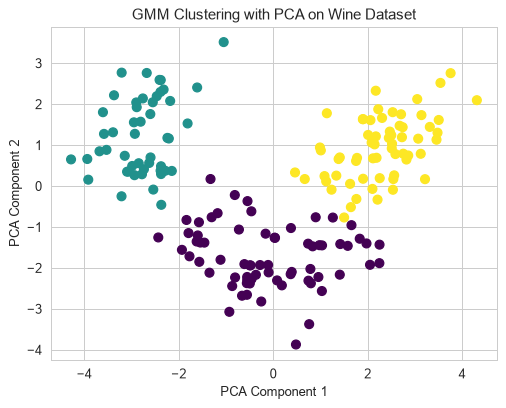

In [24]:
# Exercise 3: PCA + GMM pada dataset Wine
data = load_wine()
X = StandardScaler().fit_transform(data.data)

# PCA untuk reduksi dimensi (13 -> 2)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print('Explained variance ratio PC1, PC2:', pca.explained_variance_ratio_.round(3),
      '| total:', round(pca.explained_variance_ratio_.sum(), 3))

# Latih Gaussian Mixture Model
gmm = GaussianMixture(n_components=3, random_state=2024)
y_gmm = gmm.fit_predict(X_pca)

# Tambahan: evaluasi terhadap kelas asli (kultivar anggur)
print('ARI GMM (PCA 2D) vs kelas asli:', round(adjusted_rand_score(data.target, y_gmm), 3))
print('Silhouette (ruang PCA)        :', round(silhouette_score(X_pca, y_gmm), 3))
display(pd.crosstab(pd.Series(data.target, name='kelas asli'),
                    pd.Series(y_gmm, name='komponen GMM')))

# Visualisasi hasil klasterisasi
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_gmm, cmap='viridis', s=50)
plt.title("GMM Clustering with PCA on Wine Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

**Interpretasi:**

- Dua komponen utama menjelaskan **55.4%** variansi (PC1 36.2%, PC2 19.2%) — cukup untuk memisahkan kultivar walaupun hampir separuh informasi dibuang.
- GMM pada ruang PCA mencapai **ARI 0.914** dan silhouette 0.559. Tabel kontingensi: kelas 0 terkumpul sempurna (59/59), kelas 2 hampir sempurna (47 dari 48), dan kelas 1 — yang berada di tengah plot PCA — menyumbang sebagian besar kesalahan (67 benar, 1 + 3 tersebar). Hanya **5 dari 178** sampel (≈2.8%) yang berbeda dari kelas asli.
- Kombinasi standardisasi + PCA + model probabilistik ini menunjukkan bahwa pada data nyata berdimensi tinggi, reduksi dimensi sebelum clustering dapat menghasilkan kelompok yang sangat sesuai dengan kategori sebenarnya.

## Ringkasan Chapter 10

1. **Clustering adalah unsupervised learning** yang mengelompokkan titik berdasarkan kemiripan tanpa label. Definisi "klaster" berbeda-beda (centroid, hierarki, kepadatan, graf, model probabilistik), dan karena hampir semuanya berbasis jarak, **standardisasi fitur** dan **visualisasi awal** adalah langkah wajib. Clustering selalu menghasilkan klaster, bahkan pada data tanpa struktur.
2. **K-Means** meminimalkan inertia $\sum_k\sum_{\mathbf x\in C_k}\lVert\mathbf x-\boldsymbol\mu_k\rVert^2$ lewat iterasi assignment–update (Lloyd) dengan inisialisasi k-means++. Cepat dan scalable, tetapi mengasumsikan klaster cembung, bulat, dan berukuran mirip. $K$ dipilih dengan **elbow method** dan **silhouette**; pada data chapter ini keduanya menunjuk $K=2$ (inertia 600 → 23.7; silhouette 0.880) karena empat blob tersusun sebagai dua pasangan yang tumpang tindih.
3. **Hierarchical (agglomerative) clustering** menggabungkan klaster secara bertahap menurut linkage (ward, complete, average, single) dan menghasilkan **dendrogram**; celah tinggi terbesar (5.2 → 34.0) menunjukkan jumlah klaster alami. Ward hampir identik dengan K-Means (ARI 0.882), sedangkan single/average linkage rawan *chaining* dan klaster berisi satu titik.
4. **DBSCAN** mendefinisikan klaster sebagai wilayah padat (core/border/noise) dengan parameter `eps` dan `min_samples`; tidak memerlukan $K$, menangani bentuk sembarang, dan menandai outlier dengan −1. `eps` dipilih lewat **k-distance plot** (siku ≈0.17–0.25 pada data moons); rentang `eps` yang baik sempit (0.1 → 18 klaster, 0.2 → 2 klaster, 0.3 → 1 klaster).
5. **Evaluasi:** metrik internal — **silhouette** (↑, $[-1,1]$), **Davies–Bouldin** (↓), **Calinski–Harabasz** (↑) — dan metrik eksternal **ARI** (↑, terkoreksi peluang) bila label tersedia. Pada data blob, K-Means $K=4$ memperoleh silhouette 0.534, DB 0.702, CH ≈8671, ARI 0.814; metrik internal lebih menyukai $K=2$ atau 3, bukti bahwa "pemisahan terbaik" tidak sama dengan "struktur pembangkit".
6. **Memilih algoritma** bergantung pada bentuk klaster, noise, ukuran data, dan dimensi. Eksperimen pada blobs/moons/circles menunjukkan K-Means & Ward unggul pada klaster bulat tetapi gagal total pada cincin (ARI ≈0), sedangkan DBSCAN dan Spectral memisahkan cincin dengan sempurna (ARI 1.0).
7. **Spectral clustering** memakai eigenvektor Laplacian graf kemiripan lalu K-Means di ruang embedding — efektif untuk bentuk non-convex (ARI 1.0 pada moons ber-noise kecil). **GMM** adalah soft clustering berbasis campuran Gaussian yang dilatih dengan EM; memberi `predict_proba` (40 titik dengan keyakinan < 0.9) dan dapat dipilih jumlah komponennya dengan BIC, tetapi klasternya berbentuk elips sehingga kurang cocok untuk bulan sabit (ARI 0.526).
8. **Latihan** menerapkan semuanya pada data nyata: K-Means pada Iris (ARI 0.730; setosa terpisah sempurna, versicolor–virginica tumpang tindih), DBSCAN vs K-Means pada moons (ARI 0.948 vs 0.507), serta standardisasi + PCA + GMM pada Wine (ARI 0.914, hanya 5 dari 178 sampel berbeda dari kultivar asli).